# The memento Pattern

## Problem

Need to **restore an object back to its previous state** :
* "undo" use case
* "rollback" operations (when dealing with transactions and you need to roll back an operation on error)

But!!! Directly exposing the internal state would:
* break encapsulation, 
* making the object's implementation vulnerable to external manipulation
* and harder to maintain.

### When to Use the Memento Pattern:

1. **Preserving Object History**: Apply it when you need to maintain a record of an object’s state changes over time.
Undo/Redo Functionality: Implement it to enable undo and redo operations, allowing users to revert to previous states effortlessly.

2. **Checkpointing or Snapshotting**: Utilize it in systems requiring periodic checkpoints or snapshots of their states for recovery or analysis.

3. M**anaging State Transitions**: Employ it when managing complex state transitions in an application without altering the objects' integrity.

## Solution

The **Memento** Design Pattern helps save and restore an object's state **without exposing its internal details**.

### Components of Memento

1. **Originator**
* the actual owner of that state
* the object whose state we want to save and restore
* instead of other objects trying to copy its state from the “outside,” this class itself can make the ***snapshot*** since it has full access to its own state
* the copy of the object’s state is stored in a special object called **memento** - > the `Originator reates a Memento` object to store its state

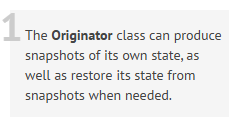
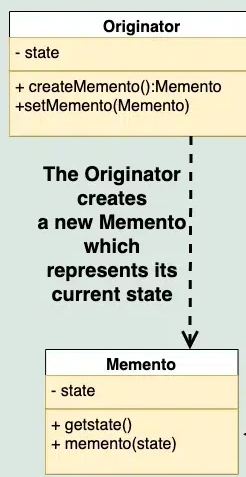

2. **Memento**
* This is an immutable object (the lock box that is written and read by the Originator) that stores the state of the Originator. 
* It has (usually) 2 main methods: `getState()` to retrieve the saved state and `setState(`) to set the state.
* But the most common practice is to make the *Memento immutable* and pass it the data only once, via the constructor.

3. **Caretaker**
* This is responsible for keeping track of the Mementos (the `Originator’s history`)
* It doesn't know the details of the state stored in the Memento 
* but can request Mementos from the Originator to save or restore its state from a Memento
* when the Originator has to travel back in history, the Caretaker `fetches the topmost memento` from the stack and passes it to the originator’s restoration method.


4. **Client**:
* Typically represented as the part of the application or system that interacts with the Originator and Caretaker to achieve specific functionality.
* The client `initiates requests to save or restore` the state of the Originator through the Caretaker.

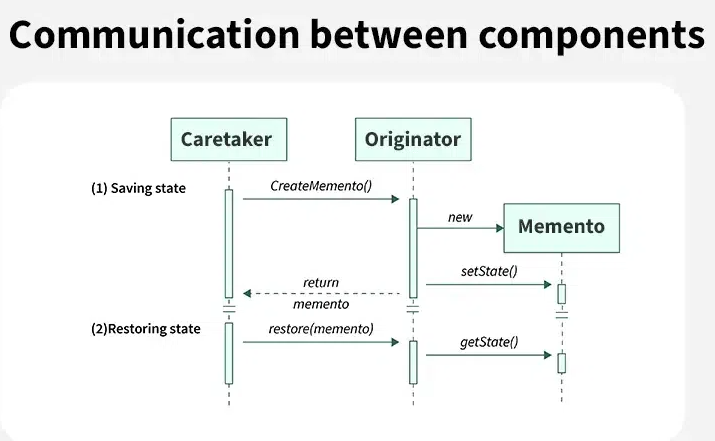

1. Client: The client initiates the process by requesting the Originator to perform some operation that may modify its state or require the state to be saved. For example, the client might trigger an action like "save state" or "restore state."
2. Originator: The Originator either produces a Memento to save its current state (if the request is to save state) or retrieves a Memento to restore its prior state (if the request is to restore state).
3. Caretaker: The Caretaker acts as an intermediary between the client and the Originator, managing the Memento objects:
* The caretaker calls the createMemento() method on the originator asking the originator to pass it a memento object.
* At this point the originator creates a memento object saving its internal state and passes the memento to the caretaker.
* The caretaker maintains the memento object and performs the operation. In case of the need to undo the operation, the caretaker calls the setMemento() method on the originator passing the maintained memento object.
* The originator would accept the memento, using it to restore its previous state.

## Implementation

This version of an implementation is suitable for programming languages that don’t support nested classes:
* Caretakers interact with Memento via a predefined interface, restricting access to metadata methods

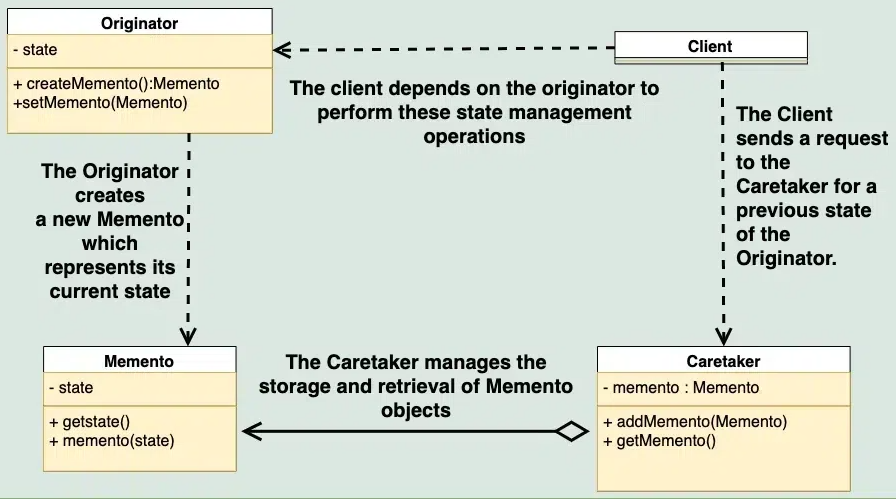

### Check list

1. Identify the roles of “caretaker” and “originator”.
2. Create a Memento class and declare the originator a friend.
3. Caretaker knows when to "check point" the originator.
4. Originator creates a Memento and copies its state to that Memento.
5. Caretaker holds on to (but cannot peek into) the Memento.
6. Caretaker knows when to "roll back" the originator.
7. Originator reinstates itself using the saved state in the Memento.

## Example 1: Memento Pattern Implementation in Python

In [5]:
class Originator:
    def __init__(self, state):
        self._state = state

    def create_memento(self):
        return Memento(self._state)

    def restore(self, memento):
        self._state = memento.get_state()

    def set_state(self, state):
        self._state = state

    def get_state(self):
        return self._state

In [6]:
class Memento:
    def __init__(self, state):
        self._state = state

    def get_state(self):
        return self._state

In [7]:
class Caretaker:
    def __init__(self):
        self._mementos = []

    def add_memento(self, memento):
        self._mementos.append(memento)

    def get_memento(self, index):
        return self._mementos[index]

In [9]:
#Client

# Instantiate classes
originator = Originator("Initial state")
caretaker = Caretaker()

print(originator.get_state())

# Store object state
caretaker.add_memento(originator.create_memento())

# Modify object state
originator.set_state("Modified state")
print(originator.get_state())

# Restore object state
originator.restore(caretaker.get_memento(0))
print(originator.get_state())

Initial state
Modified state
Initial state


## Example 2: Undo-, redo features for a text editor

Imagine we have a text editor with undo and redo functionality

**Memento**: A container capturing an object’s state, offering retrieval methods without external interference

In [1]:
class Memento:
    def __init__(self, state):
        self._state = state

    def get_state(self):
        return self._state

**Originator**: Manages the object’s state, providing methods for its storage and retrieval.

In [2]:
class TextEditor:
    def __init__(self):
        self._text = ""

    def write(self, text):
        self._text += text

    def get_text(self):
        return self._text

    def create_memento(self):
        return Memento(self._text)

    def restore(self, memento):
        self._text = memento.get_state()

**Caretaker**: Safeguards Mementos without altering their content, storing them for future use.

In [3]:
class History:
    def __init__(self):
        self._history = []

    def push(self, memento):
        self._history.append(memento)

    def pop(self):
        if self._history:
            return self._history.pop()

In [4]:
# Usage == Client

editor = TextEditor()
history = History()

editor.write("Hello, ")
history.push(editor.create_memento())

editor.write("from Hanna!")
history.push(editor.create_memento())

print("Current Text:", editor.get_text())

editor.restore(history.pop())
print("Undo:", editor.get_text())

editor.restore(history.pop())
print("Undo:", editor.get_text())


Current Text: Hello, from Hanna!
Undo: Hello, from Hanna!
Undo: Hello, 


## Example 3: Game Save System

The Memento Design Pattern helps save and reload game progress. 

This example shows how the pattern manages and brings back game states.

We’ll use classes like :
* Originator for managing the game, 
* Memento for saving states, 
* and Caretaker for handling saves.

**Step 1: Originator Game**

Define the Game class as the Originator, representing the game whose state needs saving.

In [10]:
class Game:
    def __init__(self):
        self._state = None
        # Adding GameLevel attribute for state change demonstration
        self._level = 1

    def play(self):
        # Simulate game progress by increasing the game level
        self._level += 1
        print(f"Advanced to level {self._level}")

    def create_memento(self):
        # Storing the current game level as part of the state
        return GameState({"level": self._level})

    def restore(self, memento):
        self._state = memento.get_state()
        # Retrieving the stored game level
        self._level = self._state.get("level", 1)

**Step 2: Memento GameState**

Create the GameState class as the Memento, capturing and storing the game’s state.

In [11]:
class GameState:
    def __init__(self, state):
        self._state = state

    def get_state(self):
        return self._state

**Step 3: Caretaker GameSaver**

Implement the GameSaver class as the Caretaker, managing game saves.

In [12]:
class GameSaver:
    def __init__(self):
        self._saves = {}

    def save_game(self, name, state):
        self._saves[name] = state

    def load_game(self, name):
        return self._saves[name]

**Client** Code

Demonstrate the usage of the Memento pattern.

In [13]:
# Instantiate classes
game = Game()
game_saver = GameSaver()

# Play the game and save state
game.play()
saved_state = game.create_memento()
game_saver.save_game("save_1", saved_state)

# Advance game further
game.play()

# Load and restore saved state
loaded_state = game_saver.load_game("save_1")
game.restore(loaded_state)

# Check restored state
print(f"Restored to level {game._level}")

Advanced to level 2
Advanced to level 3
Restored to level 2
